In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [ ]:
df = pd.read_csv('data.csv')
#Just to make the index start from 1
df.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-tax net Int

In [ ]:
np.shape(df)

(6819, 96)

In [ ]:
from sklearn import preprocessing

In [ ]:
df=df.to_numpy()

In [ ]:
df

array([[1.        , 0.37059426, 0.42438945, ..., 0.56405011, 1.        ,
        0.01646874],
       [1.        , 0.46429094, 0.53821413, ..., 0.57017495, 1.        ,
        0.02079431],
       [1.        , 0.42607127, 0.49901875, ..., 0.56370608, 1.        ,
        0.01647411],
       ...,
       [0.        , 0.47272461, 0.533744  , ..., 0.5651584 , 1.        ,
        0.09764874],
       [0.        , 0.50626432, 0.5599106 , ..., 0.56530151, 1.        ,
        0.04400945],
       [0.        , 0.49305319, 0.57010467, ..., 0.56516694, 1.        ,
        0.23390224]])

In [ ]:
df=np.transpose(df)

In [ ]:
y = np.transpose(df[0])
X = np.transpose(df[1:])

In [ ]:
np.shape(X),np.shape(y)

((6819, 95), (6819,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train, X_train_val, y_train, y_train_val = train_test_split(X_train, y_train, test_size=0.15, random_state=0)

In [ ]:
np.shape(X_train),np.shape(y_train),np.shape(X_test),np.shape(y_test)

((4636, 95), (4636,), (1364, 95), (1364,))

In [ ]:
np.shape(X_train_val),np.shape(y_train_val)

((819, 95), (819,))

In [ ]:
# import evaluation tools
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
from sklearn.model_selection import PredefinedSplit

In [ ]:
new_X_data=np.append(X_train, X_train_val,axis=0)

In [ ]:
np.shape(new_X_data)

(5455, 95)

In [ ]:
#Check is the first part of new_X_data are the same with the X_resampled
(new_X_data[0:np.shape(X_train)[0]]==X_train).all()

True

In [ ]:
new_y_data=np.append(y_train, y_train_val,axis=0)

In [ ]:
np.shape(new_y_data)

(5455,)

In [ ]:
#Check is the first part of new_X_data are the same with the X_resampled
(new_y_data[0:np.shape(y_train)[0]]==y_train).all()

True

In [ ]:
test_fold=[]

In [ ]:
#Next part is used to separate training set and validation set
#If we do not want to use data in that index as a validation set or testing set,
#set the value to be -1 for the index
#or else, set it as number larger or equal to 0 to 3.
#In this example, we only want to have four validation set
#which is the validation set we splitted out from
#the unprocessed training dataset.
#because we want the model applicable on the test dataset
#which is not being oversampled or outliers removed.
#We only use 0 to 3 which means we only train four times by using
#those data whose labels as 0 to 3 as the validation set
#Example is on the words next to this block

# >>> X = np.array([[1, 2], [3, 4], [1, 2], [3, 4]])
# >>> y = np.array([0, 0, 1, 1])
# >>> test_fold = [0, 1, -1, 1]
# >>> ps = PredefinedSplit(test_fold)
# >>> ps.get_n_splits()
# 2
# >>> print(ps)
# PredefinedSplit(test_fold=array([ 0,  1, -1,  1]))
# >>> for i, (train_index, test_index) in enumerate(ps.split()):
# ...     print(f"Fold {i}:")
# ...     print(f"  Train: index={train_index}")
# ...     print(f"  Test:  index={test_index}")
# Fold 0:
#  Train: index=[1 2 3]
#  Test:  index=[0]
# Fold 1:
#  Train: index=[0 2]
#  Test:  index=[1 3]

In [ ]:
for i in range(np.shape(X_train)[0]):
  test_fold.append(-1)
j=0
for i in range(np.shape(X_train_val)[0]):
  test_fold.append(j)
  if j<3:
    j=j+1
  else:
    j=0

In [ ]:
ps = PredefinedSplit(test_fold=test_fold)

In [ ]:
depths = np.arange(1,2)
num_leafs = np.arange(2,3)
min_samples_leaf= np.arange(2,3)

In [ ]:
try_grid = [{'max_depth':depths,
        'max_leaf_nodes':num_leafs,
        'min_samples_leaf':min_samples_leaf}]

In [ ]:
#We want to use our own validation set
#See https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.PredefinedSplit.html#sklearn.model_selection.PredefinedSplit

In [ ]:
DTM = GridSearchCV(DecisionTreeClassifier(), param_grid=try_grid, cv=ps)

In [ ]:
#The code next line (DTM.fit(X_train, y_train)) could cost long time to work, please try only if you have
#time
#cv=ps already help us to split new_X_data and new_y_data into training set
# and validation set, that is why the input next line
# is new_X_data and new_y_data instead of X_resampled and y_resampled

In [ ]:
DTM.fit(new_X_data, new_y_data)

GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  1,  2])),
             estimator=DecisionTreeClassifier(),
             param_grid=[{'max_depth': array([1]), 'max_leaf_nodes': array([2]),
                          'min_samples_leaf': array([2])}])

In [ ]:
DTM.best_params_

{'max_depth': 1, 'max_leaf_nodes': 2, 'min_samples_leaf': 2}

In [ ]:
DTM.best_score_

0.9731527977044476

In [ ]:
my_model=DecisionTreeClassifier(max_leaf_nodes=DTM.best_params_['max_leaf_nodes'],\
                max_depth=DTM.best_params_['max_depth'],\
                min_samples_leaf=DTM.best_params_['min_samples_leaf'])

In [ ]:
my_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=1, max_leaf_nodes=2, min_samples_leaf=2)

In [ ]:
print("Non-bankrupted(value=0): ",np.count_nonzero(y_train==0))
print("Bankrupted(value=1): ",np.count_nonzero(y_train))

Non-bankrupted(value=0):  4484
Bankrupted(value=1):  152


In [ ]:
# import evaluation tools for plotting the curve
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
#Check the cross-evaluation accuracy by using ROC
#Although it is not necessary

In [ ]:
tree_score = cross_val_score(my_model, X_train, y_train, cv=10)
print(tree_score.mean())

0.9672134505101662


In [ ]:
tree_preds = cross_val_predict(my_model, X_train, y_train, cv=10)

In [ ]:
print (f'This is prediction for decision tree: \n {tree_preds}')

This is prediction for decision tree: 
 [0. 0. 0. ... 0. 0. 0.]


In [ ]:
np.count_nonzero(tree_preds==0),np.count_nonzero(tree_preds)

(4636, 0)

In [ ]:
print(accuracy_score(y_train, tree_preds, normalize=True, sample_weight=None))

0.9672131147540983


In [ ]:
print(f'This is confusion matrix for decision tree: \n{confusion_matrix(y_train, tree_preds)}')

This is confusion matrix for decision tree: 
[[4484    0]
 [ 152    0]]


In [ ]:
tree_preds_prob = cross_val_predict(my_model, X_train, y_train, cv=10, method="predict_proba")

In [ ]:
tree_preds_prob

array([[0.97692119, 0.02307881],
       [0.97692119, 0.02307881],
       [0.97692119, 0.02307881],
       ...,
       [0.97693817, 0.02306183],
       [0.97693817, 0.02306183],
       [0.97693817, 0.02306183]])

In [ ]:
tree_preds_prob_1 = cross_val_predict(my_model, X_train, y_train, cv=10, method="predict_proba")[:,1]

In [ ]:
tree_preds_prob_1

array([0.02307881, 0.02307881, 0.02307881, ..., 0.02306183, 0.02306183,
       0.02306183])

In [ ]:
tree_fpr, tree_tpr, thresholds = roc_curve(y_train, tree_preds_prob_1)

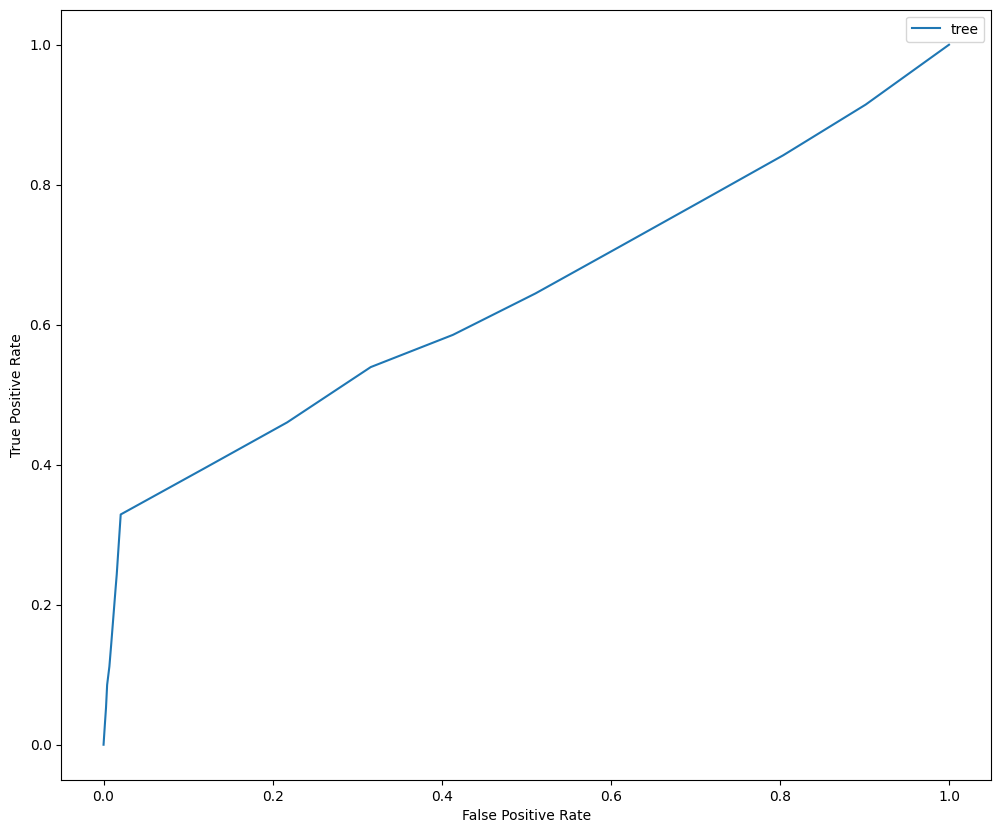

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(12, 10))
plt.plot(tree_fpr, tree_tpr, label="tree")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
from sklearn.metrics import auc

# Get AUC
tree_auc = auc(tree_fpr, tree_tpr)

# Print results
pd.DataFrame({"Model":['Decision Tree'], "AUC":[tree_auc]})

,Model,AUC
0,Decision Tree,0.642956


In [ ]:
final_test = my_model.predict(X_test)
final_test

array([0., 0., 0., ..., 0., 0., 0.])

In [ ]:
# evaluate final test result
print("Accuracy:",accuracy_score(y_test, final_test, normalize=True, sample_weight=None))
print("Confusion Matrix:", '\n', confusion_matrix(y_test, final_test))

Accuracy: 0.966275659824047
Confusion Matrix: 
 [[1318    0]
 [  46    0]]


In [ ]:
#The number for bankrupted
np.count_nonzero(y_test)

46

In [ ]:
#The number for non-bankrupted
np.shape(y_test)[0]-np.count_nonzero(y_test)

1318

In [ ]:
#The accuracy of guessing all companies did not go bankrupted
random_guessing_accuracy=1-(np.count_nonzero(y_test)/(np.shape(y_test)[0]))

In [ ]:
random_guessing_accuracy

0.966275659824047

In [ ]:
model_accuracy=accuracy_score(y_test, final_test, normalize=True, sample_weight=None)

In [ ]:
model_accuracy

0.966275659824047

In [ ]:
if model_accuracy>random_guessing_accuracy:
  print("Good model")
else:
  print("Not bad, but expect better.")

Not bad, but expect better.


In [ ]:
from sklearn import tree
from matplotlib import pyplot as plt

In [ ]:
new_df=pd.read_csv('data.csv')

In [ ]:
fig = plt.figure(figsize=(200,200))
_ = tree.plot_tree(my_model,feature_names=list(new_df)[1:], class_names=['Not Bankrupted','Bankrupted'], max_depth=5,filled=True)

In [ ]:
#Necessary part

In [ ]:
#Check the accuracy on testing dataset by using ROC

In [ ]:
new_tree_score = accuracy_score(y_test, final_test, normalize=True, sample_weight=None)
print(new_tree_score)

0.966275659824047


In [ ]:
new_tree_preds = final_test

In [ ]:
print (f'This is prediction for decision tree: \n {new_tree_preds}')

This is prediction for decision tree: 
 [0. 0. 0. ... 0. 0. 0.]


In [ ]:
np.count_nonzero(new_tree_preds==0),np.count_nonzero(new_tree_preds)

(1364, 0)

In [ ]:
print(accuracy_score(y_test, new_tree_preds, normalize=True, sample_weight=None))

0.966275659824047


In [ ]:
print(f'This is confusion matrix for decision tree: \n{confusion_matrix(y_test, new_tree_preds)}')

This is confusion matrix for decision tree: 
[[1318    0]
 [  46    0]]


In [ ]:
new_tree_preds_prob = my_model.predict_proba(X_test)

In [ ]:
new_tree_preds_prob

array([[0.97942295, 0.02057705],
       [0.97942295, 0.02057705],
       [0.97942295, 0.02057705],
       ...,
       [0.97942295, 0.02057705],
       [0.97942295, 0.02057705],
       [0.97942295, 0.02057705]])

In [ ]:
new_tree_preds_prob_1 = my_model.predict_proba(X_test)[:,1]

In [ ]:
new_tree_fpr, new_tree_tpr, new_thresholds = roc_curve(y_test, new_tree_preds_prob_1)

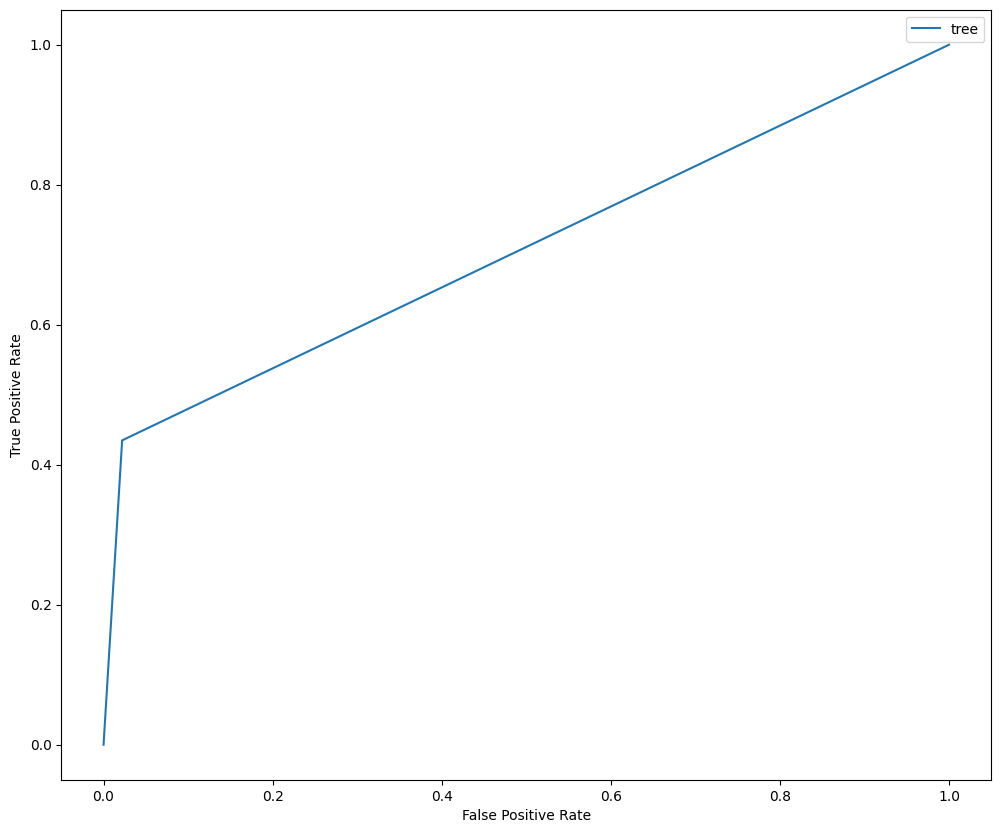

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(12, 10))
plt.plot(new_tree_fpr, new_tree_tpr, label="tree")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
from sklearn.metrics import auc

# Get AUC
new_tree_auc = auc(new_tree_fpr, new_tree_tpr)

# Print results
pd.DataFrame({"Model":['Decision Tree'], "AUC":[new_tree_auc]})

,Model,AUC
0,Decision Tree,0.70639


In [ ]:
test_confusion_matrix=confusion_matrix(y_test, new_tree_preds)

In [ ]:
print("Recall=TP/(TP+FN)= ",test_confusion_matrix[1,1]/(test_confusion_matrix[1,1]+test_confusion_matrix[1,0]))

Recall=TP/(TP+FN)=  0.0


In [ ]:
#Investor perspective: Highly aware if the company would go bankrupt
#Set the prediction threshold to be 0.15, if the probability of
#going bankrupt is larger than 15%, then it would be predictied as True.

In [ ]:
investor_prediction=np.copy(new_tree_preds_prob)

In [ ]:
investor_predict_bankeuptcy=[]

In [ ]:
for i in range(np.shape(investor_prediction)[0]):
  if investor_prediction[i,1]<=0.15:
    investor_predict_bankeuptcy.append(0)
  else:
    investor_predict_bankeuptcy.append(1)

In [ ]:
print(investor_predict_bankeuptcy)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [ ]:
print(f'This is confusion matrix for decision tree in investor perspective: \n{confusion_matrix(y_test, investor_predict_bankeuptcy)}')

This is confusion matrix for decision tree in investor perspective: 
[[1289   29]
 [  26   20]]


In [ ]:
investor_confusion_matrix=np.copy(confusion_matrix(y_test, investor_predict_bankeuptcy))

In [ ]:
print("In investor perspective: Recall=TP/(TP+FN)= ",investor_confusion_matrix[1,1]/(investor_confusion_matrix[1,1]+investor_confusion_matrix[1,0]))

In investor perspective: Recall=TP/(TP+FN)=  0.43478260869565216


In [ ]:
#We set cost as getting FP is 1, while FN is 10
#FP means investors would falsely identify a non-bankrupt company as bankrupt
#FN means investors would falsely identify a bankrupt company as non-bankrupt
#The cost of FN should be much higher than FP.
#Higher the cost, the worse it is.

In [ ]:
print("Cost:",investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10)

Cost: 289


In [ ]:
cost=investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10

In [ ]:
#We set gain of TP is 5, while TN is 0.5
#TP means investors would correctly identify a bankrupt company as bankrupt
#TN means investors would correctly identify a non-bankrupt company as non-bankrupt
#The gain of TP should be higher than TN
#In investors perspective, FP and FN should be more aware
#The value of cost should be larger than the value of gain
#because even it is non-bankrupt, it does not mean investor
#would earn a lot in that company
#Higher the gain, the better it is.

In [ ]:
print("Gain:", investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5)

Gain: 228.9


In [ ]:
#Net cost is used to calculate the cost including the earning when we correctly identify
#Net cost=cost-gain
#Higher the net cost, the worse it is.

In [ ]:
gain=investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5

In [ ]:
print("Net cost", cost-gain)

Net cost 60.099999999999994
